# Comparison of Strategies 1, 2 and 3
**Topic:** LLM-based reasoning strategies in FrozenLake-v1 · **Platform:** Google Colab (CPU is enough — no LLM is loaded)

This notebook only **reads the CSV files** written by the three strategy notebooks and builds the comparison tables and figures for the paper:

| File | Written by |
|---|---|
| `summary_s1.csv`, `steps_s1.csv` | `Strategy1_Structured_Prompt_Reasoner.ipynb` |
| `summary_s2.csv`, `steps_s2.csv` | `Strategy2_Parameter_Tuned_Reasoner.ipynb` |
| `summary_s3.csv`, `steps_s3.csv`, `trials_s3.csv` | `Strategy3_Memory_Verifier_Reflexion.ipynb` |

**Where the files are read from** (first match wins): the Colab working directory (drag the CSVs into the Files panel), then a local clone of the repo (`results/experiment_results_strategy_k/`), then the GitHub repo.
Older result folders that only have `summary_all.csv` for Strategy 3 are also accepted.

| Figure | Question it answers |
|---|---|
| 1 · success rate with 95% CI | which configuration solves the most maps, and is the difference larger than the noise of 10 maps? |
| 2 · outcome breakdown | how do the headline agents fail (hole vs timeout)? |
| 3 · accuracy vs reproducibility / cost | accuracy vs creativity vs reproducibility, and what the reasoning costs |
| 4 · step-level decisions | quality of each individual decision |
| 5 · per-map success | which maps are hard for which agent |
| 6 · reasoning quality | are the stated reasoning and the chosen action correct and consistent? |

## 1. Setup

In [1]:
# gymnasium is only used to rebuild the 10 maps for the reasoning-quality check
%pip install -q "gymnasium>=1.0"

In [2]:
import ast
import glob
import io
import os
import re
import urllib.request
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from gymnasium.envs.toy_text.frozen_lake import generate_random_map

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
os.makedirs("figures", exist_ok=True)

REPO_RAW = "https://raw.githubusercontent.com/alessamelo/llm-reasoning-strategies-frozenlake/main/results"
FOLDER = {"S1": "experiment_results_strategy_1", "S2": "experiment_results_strategy_2", "S3": "experiment_results_strategy_3"}

def read_csv(strategy, filename):
    # Looks for the file locally first, then on GitHub. Returns None if it does not exist anywhere.
    for path in [filename, f"results/{FOLDER[strategy]}/{filename}", *glob.glob(f"**/{FOLDER[strategy]}/{filename}", recursive=True)]:
        if os.path.exists(path):
            print(f"{strategy}: {filename:16s} ← {path}")
            return pd.read_csv(path)
    try:
        with urllib.request.urlopen(f"{REPO_RAW}/{FOLDER[strategy]}/{filename}", timeout=30) as r:
            print(f"{strategy}: {filename:16s} ← GitHub")
            return pd.read_csv(io.BytesIO(r.read()))
    except Exception:
        return None

# Colors: one hue per strategy (fixed order), status colors only for episode outcomes.
STRAT_COLOR = {"S1": "#2a78d6", "S2": "#eb6834", "S3": "#1baf7a"}
OUTCOME_COLOR = {"success rate": "#0ca30c", "hole rate": "#d03b3b", "timeout rate": "#a3a29b"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False})

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")              # vector, for LaTeX
    fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 2. Load results

In [3]:
summaries, steps = [], []
for s in ["S1", "S2", "S3"]:
    summ = read_csv(s, f"summary_{s.lower()}.csv")
    if summ is None and s == "S3":                                       # older S3 output: summary_all.csv with "S3 · " rows
        summ = read_csv(s, "summary_all.csv")
        if summ is not None:
            summ = summ[summ.iloc[:, 0].str.startswith("S3")]
            summ.iloc[:, 0] = summ.iloc[:, 0].str.replace(r"^S3 · ", "", regex=True)
            print("   (old format: no steps_s3.csv, no episode counts — S3 is missing from the step-level analyses)")
    if summ is None:
        print(f"{s}: summary NOT FOUND — run the notebook of Strategy {s[1]} first"); continue
    summ = summ.rename(columns={summ.columns[0]: "config"}).assign(strategy=s)
    summaries.append(summ)
    st = read_csv(s, f"steps_{s.lower()}.csv")
    if st is not None:
        steps.append(st.assign(strategy=s))

summary = pd.concat(summaries, ignore_index=True)
summary["label"] = summary["strategy"] + " · " + summary["config"]
summary = summary.set_index("label")
steps = pd.concat(steps, ignore_index=True) if steps else pd.DataFrame()
if len(steps):
    steps["label"] = steps["strategy"] + " · " + steps["run"]
    for col in ["pos", "next"]:
        steps[col] = steps[col].apply(ast.literal_eval)
    for col in ["parse_fail", "wall", "optimal"]:
        steps[col] = steps[col].astype(bool)
print(f"\n{len(summary)} configurations, {len(steps)} logged steps")

S1: summary_s1.csv   ← results/experiment_results_strategy_1/summary_s1.csv
S1: steps_s1.csv     ← results/experiment_results_strategy_1/steps_s1.csv
S2: summary_s2.csv   ← results/experiment_results_strategy_2/summary_s2.csv
S2: steps_s2.csv     ← results/experiment_results_strategy_2/steps_s2.csv
S3: summary_s3.csv   ← results/experiment_results_strategy_3/summary_s3.csv
S3: steps_s3.csv     ← results/experiment_results_strategy_3/steps_s3.csv

21 configurations, 5158 logged steps


## 3. Number of episodes and 95% confidence intervals
Each success rate comes from only 10 maps × repeats, so it carries a large sampling error. The **Wilson interval** gives the range compatible with the data: two configurations whose intervals overlap a lot should not be called different.

In [4]:
def n_episodes(label, row):
    if "episodes" in row and pd.notna(row["episodes"]):
        return int(row["episodes"])
    if len(steps) and label in set(steps["label"]):                         # older CSVs: count (map, rep) pairs
        return steps[steps["label"] == label].groupby(["map", "rep"]).ngroups
    return 10                                                               # unknown → 1 episode per map

def wilson(p, n, z=1.96):
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

summary["episodes"] = [n_episodes(l, r) for l, r in summary.iterrows()]
summary["successes"] = (summary["success rate"] * summary["episodes"]).round().astype(int)
lo, hi = wilson(summary["success rate"], summary["episodes"])
summary["ci low"], summary["ci high"] = lo.clip(0, 1), hi.clip(0, 1)

COLS = ["episodes", "success rate", "ci low", "ci high", "hole rate", "timeout rate", "steps (success)",
        "optimal-move rate", "parse-fail rate", "wall-bump rate", "tokens/step", "consistency"]
display(summary[COLS].round(3))

,episodes,success rate,ci low,ci high,hole rate,timeout rate,steps (success),optimal-move rate,parse-fail rate,wall-bump rate,tokens/step,consistency
label,,,,,,,,,,,,
S1 · direct,20,0.00,0.000,0.161,0.70,0.30,NaN,0.387,0.000,0.484,4.000,1.00
S1 · step_by_step,20,0.00,0.000,0.161,0.60,0.40,NaN,0.153,0.542,0.194,145.056,1.00
S1 · rules,20,0.00,0.000,0.161,0.30,0.70,NaN,0.091,0.773,0.100,224.482,1.00
S1 · structured,20,0.00,0.000,0.161,0.60,0.40,NaN,0.200,0.000,0.686,23.000,1.00
S2 · deterministic,20,0.00,0.000,0.161,0.30,0.70,NaN,0.091,0.773,0.100,224.482,1.00
S2 · exploratory,50,0.00,0.000,0.071,0.82,0.18,NaN,0.271,0.292,0.207,168.920,0.22
"S2 · T=0.3, top_p=0.8",50,0.00,0.000,0.071,0.70,0.30,NaN,0.255,0.228,0.321,146.042,0.26
"S2 · T=0.6, top_p=0.8",50,0.06,0.021,0.162,0.68,0.26,12.333,0.311,0.278,0.190,157.534,0.26
"S2 · T=1.2, top_p=0.8",50,0.02,0.004,0.105,0.84,0.14,11.000,0.251,0.296,0.237,163.821,0.20


## 4. Figure 1 — success rate of every configuration

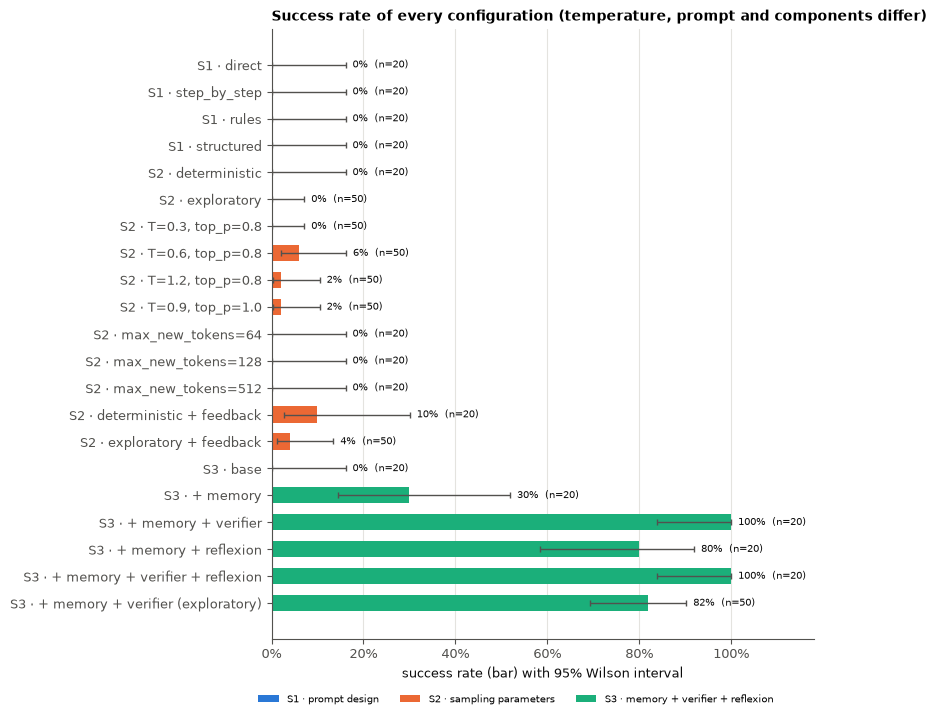

In [5]:
def fig_success(table, name, title):
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(table) + 1.2))
    y = np.arange(len(table))
    colors = [STRAT_COLOR[s] for s in table["strategy"]]
    ax.barh(y, table["success rate"], color=colors, height=0.6)
    ax.errorbar(table["success rate"], y, xerr=[table["success rate"] - table["ci low"], table["ci high"] - table["success rate"]],
                fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
    for yi, (p, hi, n) in enumerate(zip(table["success rate"], table["ci high"], table["episodes"])):
        ax.text(hi + 0.015, yi, f"{p:.0%}  (n={n})", va="center", fontsize=7.5, color=INK)
    ax.set_yticks(y, table.index); ax.invert_yaxis()
    ax.set_xlim(0, 1.18); ax.set_xticks(np.linspace(0, 1, 6)); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_xlabel("success rate (bar) with 95% Wilson interval")
    for s, c in STRAT_COLOR.items():
        ax.bar(0, 0, color=c, label={"S1": "S1 · prompt design", "S2": "S2 · sampling parameters", "S3": "S3 · memory + verifier + reflexion"}[s])
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.6 / (0.32 * len(table) + 1.2)), fontsize=7.5)
    ax.set_title(title, loc="left")
    save(fig, name)

fig_success(summary, "cmp_success_all", "Success rate of every configuration (temperature, prompt and components differ)")

## 5. Headline configurations
One row per idea, used in the remaining figures and in the main table of the paper. `HEADLINE` is chosen automatically (best S1 prompt, S2 deterministic vs exploratory, S3 base and best agent) — edit the list to change it.

In [6]:
def best(strategy, exclude=()):
    t = summary[(summary["strategy"] == strategy) & ~summary["config"].isin(exclude)]
    return t.sort_values(["success rate", "optimal-move rate"], ascending=False).index[0] if len(t) else None

S3_EXPLORATORY = "S3 · + memory + verifier (exploratory)"
HEADLINE = [best("S1"), "S2 · deterministic", "S2 · exploratory", "S3 · base",
            best("S3", exclude=["+ memory + verifier (exploratory)"]), S3_EXPLORATORY]
HEADLINE = list(dict.fromkeys(h for h in HEADLINE if h in summary.index))   # keep existing, drop duplicates
head = summary.loc[HEADLINE]
print("Headline:", *HEADLINE, sep="\n  ")
display(head[COLS].round(3))
head[COLS].round(3).to_csv("comparison_headline.csv")
summary[["strategy", "config"] + COLS].round(3).to_csv("comparison_all.csv")
print("saved: comparison_headline.csv, comparison_all.csv")

Headline:
  S1 · direct
  S2 · deterministic
  S2 · exploratory
  S3 · base
  S3 · + memory + verifier + reflexion
  S3 · + memory + verifier (exploratory)


,episodes,success rate,ci low,ci high,hole rate,timeout rate,steps (success),optimal-move rate,parse-fail rate,wall-bump rate,tokens/step,consistency
label,,,,,,,,,,,,
S1 · direct,20,0.00,0.000,0.161,0.70,0.30,NaN,0.387,0.000,0.484,4.000,1.00
S2 · deterministic,20,0.00,0.000,0.161,0.30,0.70,NaN,0.091,0.773,0.100,224.482,1.00
S2 · exploratory,50,0.00,0.000,0.071,0.82,0.18,NaN,0.271,0.292,0.207,168.920,0.22
S3 · base,20,0.00,0.000,0.161,0.60,0.40,NaN,0.200,0.000,0.686,23.000,1.00
S3 · + memory + verifier + reflexion,20,1.00,0.839,1.000,0.00,0.00,6.600,0.939,0.000,0.030,32.515,1.00
S3 · + memory + verifier (exploratory),50,0.82,0.692,0.902,0.12,0.06,8.024,0.797,0.005,0.019,33.094,0.34


saved: comparison_headline.csv, comparison_all.csv


## 6. Figure 2 — how the headline agents end their episodes

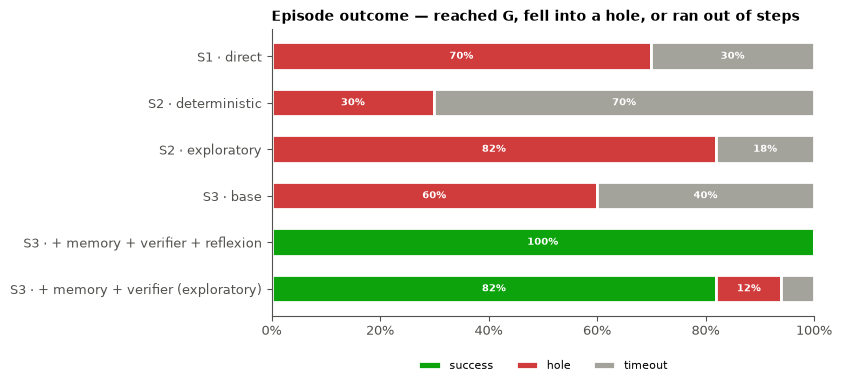

In [7]:
fig, ax = plt.subplots(figsize=(7, 0.42 * len(head) + 1.2))
left = np.zeros(len(head))
for col, c in OUTCOME_COLOR.items():
    vals = head[col].fillna(0).values
    ax.barh(range(len(head)), vals, left=left, color=c, height=0.6, edgecolor="white", linewidth=2, label=col.replace(" rate", ""))
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.08:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    left += vals
ax.set_yticks(range(len(head)), head.index); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
ax.set_title("Episode outcome — reached G, fell into a hole, or ran out of steps", loc="left")
save(fig, "cmp_outcomes")

## 7. Figure 3 — accuracy vs reproducibility vs cost
Three panels of the same size that share the rows (the headline configurations), each value written at the end of its bar.
*Success:* success rate with its 95% Wilson interval. *Reproducibility:* consistency = share of the repeats of a map that follow the same path (1 = fully reproducible). *Cost:* generated tokens per decision. Every configuration is in `comparison_all.csv` and in the table of the paper.

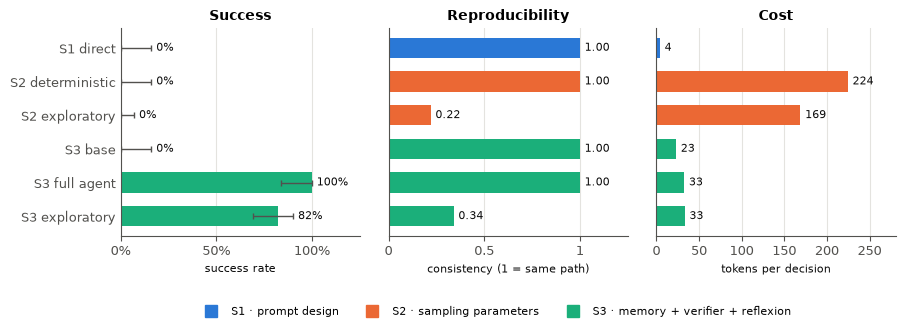

In [8]:
SHORT = {"S3 · + memory + verifier + reflexion": "S3 full agent",
         "S3 · + memory + verifier (exploratory)": "S3 exploratory"}       # short names for long labels
t3 = summary.loc[HEADLINE]
yy = np.arange(len(t3))
bar_colors = [STRAT_COLOR[s] for s in t3["strategy"]]
tok_max = float(t3["tokens/step"].max()) * 1.25
PANELS = [("success rate", "Success", "success rate", lambda v: f"{v:.0%}", 1.25),
          ("consistency", "Reproducibility", "consistency (1 = same path)", lambda v: f"{v:.2f}", 1.25),
          ("tokens/step", "Cost", "tokens per decision", lambda v: f"{v:.0f}", tok_max)]

fig, axes = plt.subplots(1, 3, figsize=(10, 0.45 * len(t3) + 0.7), sharey=True)
for ax, (col, title, xlabel, fmt, xmax) in zip(axes, PANELS):
    vals = t3[col].astype(float).fillna(0).values
    ax.barh(yy, vals, color=bar_colors, height=0.6)
    ends = vals
    if col == "success rate":
        ax.errorbar(vals, yy, xerr=[vals - t3["ci low"], t3["ci high"] - vals], fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
        ends = t3["ci high"].values                                     # write the value after the interval
    for yi, e, v in zip(yy, ends, vals):
        ax.text(e + 0.02 * xmax, yi, fmt(v), va="center", fontsize=8, color=INK)
    ax.set_xlim(0, xmax); ax.set_title(title, loc="center"); ax.set_xlabel(xlabel, fontsize=8)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
axes[0].set_xticks([0, 0.5, 1]); axes[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].set_xticks([0, 0.5, 1]); axes[1].xaxis.set_major_formatter(lambda v, _: f"{v:g}")
axes[0].set_yticks(yy, [SHORT.get(l, l.replace(" · ", " ")) for l in t3.index]); axes[0].invert_yaxis()
handles = [plt.Line2D([], [], marker="s", ls="", markersize=8, color=c,
                      label={"S1": "S1 · prompt design", "S2": "S2 · sampling parameters", "S3": "S3 · memory + verifier + reflexion"}[s])
           for s, c in STRAT_COLOR.items()]
fig.subplots_adjust(wspace=0.12, bottom=0.27)
fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=8)
save(fig, "cmp_reproducibility_cost")

## 8. Figure 4 — quality of individual decisions

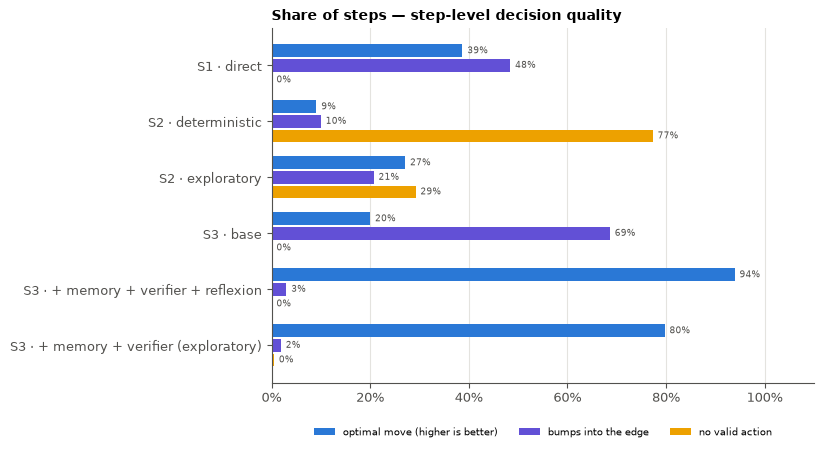

In [9]:
METRICS = [("optimal-move rate", "#2a78d6", "optimal move (higher is better)"),
           ("wall-bump rate", "#6250d6", "bumps into the edge"),
           ("parse-fail rate", "#eda100", "no valid action")]
fig, ax = plt.subplots(figsize=(7, 0.55 * len(head) + 1.3))
h = 0.26
for k, (col, c, lab) in enumerate(METRICS):
    y = np.arange(len(head)) + (k - 1) * h
    ax.barh(y, head[col].fillna(0), height=h - 0.03, color=c, label=lab)
    for yi, v in zip(y, head[col].fillna(0)):
        ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=6.5, color=INK2)
ax.set_yticks(range(len(head)), head.index); ax.invert_yaxis()
ax.set_xlim(0, 1.1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=7.5)
ax.set_title("Share of steps — step-level decision quality", loc="left")
save(fig, "cmp_step_quality")

## 9. Figure 5 — success per map
Built from the step logs (an episode is a success if its last step lands on G). Shows whether a strategy wins on all maps or only on a few easy ones.

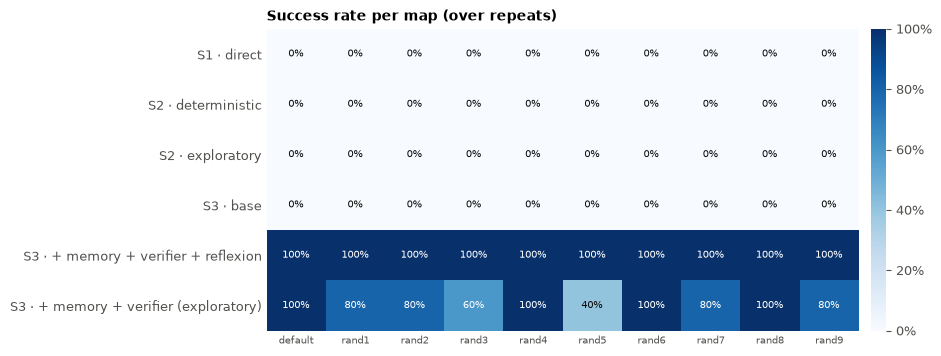

In [10]:
if len(steps):
    last = steps.sort_values("step").groupby(["label", "map", "rep"] + (["trial"] if "trial" in steps else []), dropna=False).tail(1)
    if "trial" in last:                                                   # reflexion: keep the final attempt of each map
        last = last[last["trial"].isna() | (last["trial"] == last.groupby(["label", "map", "rep"])["trial"].transform("max"))]
    per_map = (last.assign(success=last["tile"] == "G").groupby(["label", "map"])["success"].mean().unstack())
    rows = [h for h in HEADLINE if h in per_map.index]
    per_map = per_map.loc[rows, sorted(per_map.columns, key=lambda m: (m != "default", len(m), m))]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(rows) + 1.4))
    im = ax.imshow(per_map.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(per_map.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.55 else INK)
    ax.set_xticks(range(per_map.shape[1]), per_map.columns, rotation=0, fontsize=7.5); ax.set_yticks(range(len(rows)), rows)
    ax.spines[:].set_visible(False); ax.tick_params(length=0)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, format=lambda v, _: f"{v:.0%}").outline.set_visible(False)
    ax.set_title("Success rate per map (over repeats)", loc="left")
    save(fig, "cmp_per_map")
    missing = sorted(set(HEADLINE) - set(rows))
    if missing:
        print("No step log for:", *missing)
else:
    print("No steps_*.csv found — per-map figure skipped.")

## 10. Figure 6 — reasoning quality
The maps are rebuilt exactly as in the strategy notebooks, so every logged decision can be checked against the ground truth.

| Measure | Applies to | Meaning |
|---|---|---|
| safe-action rate | every run | the chosen action neither enters a hole nor hits the edge |
| safe-moves accuracy | outputs with the `Safe moves:` field (S1 `structured`, S3) | the listed safe moves are exactly the true safe moves |
| stated = taken | outputs with the `My choice:` field | the move named in the reasoning is the move in the `ACTION:` line |
| reasoning-before-action | every run | the output contains text before the first `ACTION:` (reasoning was actually written) |

rebuilt maps agree with the logged tiles: 100.0%


,safe action,safe-moves accuracy,stated = taken,reasoning before action
label,,,,
S1 · direct,0.403,NaN,NaN,0.0
S1 · step_by_step,0.181,NaN,NaN,1.0
S1 · rules,0.100,NaN,NaN,1.0
S1 · structured,0.229,0.071,0.571,1.0
S2 · deterministic,0.100,NaN,NaN,1.0
S2 · exploratory,0.393,0.000,NaN,1.0
"S2 · T=0.3, top_p=0.8",0.365,NaN,NaN,1.0
"S2 · T=0.6, top_p=0.8",0.451,0.000,NaN,1.0
"S2 · T=1.2, top_p=0.8",0.355,0.000,NaN,1.0


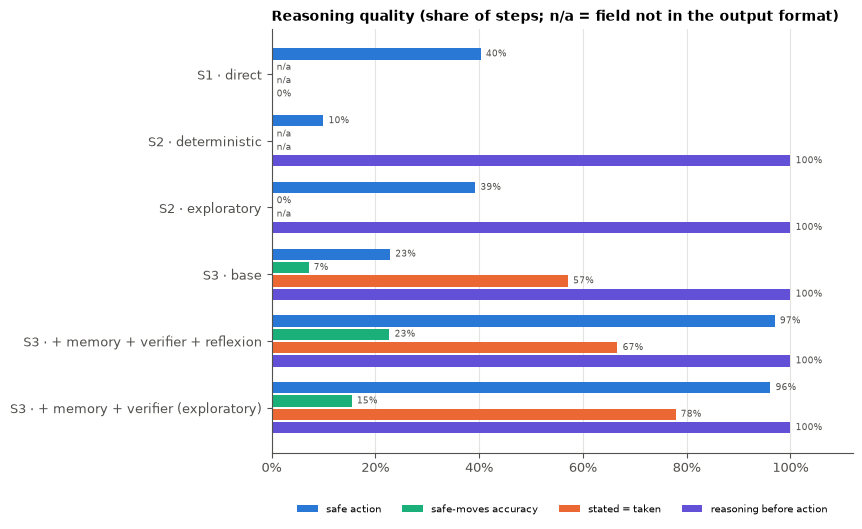

In [11]:
# Same maps as in the strategy notebooks
N_MAPS, GOAL = 10, (3, 3)
MAPS, seed = {"default": ["SFFF", "FHFH", "FFFH", "HFFG"]}, 0
while len(MAPS) < N_MAPS:
    seed += 1
    desc = generate_random_map(size=4, p=0.7, seed=seed)
    if desc not in MAPS.values():
        MAPS[f"rand{seed}"] = desc
ACTIONS, MOVES = ["LEFT", "DOWN", "RIGHT", "UP"], [(0, -1), (1, 0), (0, 1), (-1, 0)]

def target(pos, a):
    r, c = pos[0] + MOVES[a][0], pos[1] + MOVES[a][1]
    return (r, c) if 0 <= r < 4 and 0 <= c < 4 else pos

def true_safe(desc, pos):
    return {ACTIONS[a] for a in range(4) if target(pos, a) != pos and desc[target(pos, a)[0]][target(pos, a)[1]] != "H"}

if len(steps):
    # sanity check: the rebuilt maps match the tiles in the logs
    ok = steps.apply(lambda r: r["map"] in MAPS and MAPS[r["map"]][r["next"][0]][r["next"][1]] == r["tile"], axis=1).mean()
    print(f"rebuilt maps agree with the logged tiles: {ok:.1%}")

    def first_answer(text):                         # S3 verifier logs keep every attempt; the 1st one is the model's own reasoning
        return str(text).split("[verifier]")[0]

    def field(text, name):
        m = re.search(rf"{name}\s*:\s*(.*)", text, re.IGNORECASE)
        return {w.upper() for w in re.findall(r"\b(LEFT|DOWN|RIGHT|UP)\b", m.group(1), re.IGNORECASE)} if m else None

    def quality(r):
        t, desc = first_answer(r["text"]), MAPS[r["map"]]
        stated_safe, choice = field(t, "Safe moves"), field(t, "My choice")
        tag = re.search(r"ACTION\s*\**\s*[:=]\s*[\*\[<\s]*(LEFT|DOWN|RIGHT|UP)", t, re.IGNORECASE)
        return pd.Series({
            "safe action": (not r["parse_fail"]) and (not r["wall"]) and r["tile"] != "H",
            "safe-moves accuracy": np.nan if stated_safe is None else float(stated_safe == true_safe(desc, r["pos"])),
            "stated = taken": (np.nan if not choice or not tag else float(choice == {tag.group(1).upper()})),
            "reasoning before action": len(t[:tag.start()].strip()) > 20 if tag else len(t.strip()) > 20,
        })

    q = pd.concat([steps[["label"]], steps.apply(quality, axis=1)], axis=1).groupby("label").mean()
    q = q.loc[[l for l in summary.index if l in q.index]]
    display(q.round(3))
    q.round(3).to_csv("comparison_reasoning_quality.csv")

    qh = q.loc[[h for h in HEADLINE if h in q.index]]
    QCOLS = [("safe action", "#2a78d6"), ("safe-moves accuracy", "#1baf7a"), ("stated = taken", "#eb6834"), ("reasoning before action", "#6250d6")]
    fig, ax = plt.subplots(figsize=(7.5, 0.7 * len(qh) + 1.3))
    h = 0.2
    for k, (col, c) in enumerate(QCOLS):
        y = np.arange(len(qh)) + (k - 1.5) * h
        vals = qh[col].astype(float)
        ax.barh(y, vals.fillna(0), height=h - 0.03, color=c, label=col)
        for yi, v in zip(y, vals):
            ax.text((0 if np.isnan(v) else v) + 0.01, yi, "n/a" if np.isnan(v) else f"{v:.0%}", va="center", fontsize=6.5, color=INK2)
    ax.set_yticks(range(len(qh)), qh.index); ax.invert_yaxis()
    ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=7.5)
    ax.set_title("Reasoning quality (share of steps; n/a = field not in the output format)", loc="left")
    save(fig, "cmp_reasoning_quality")
else:
    print("No steps_*.csv found — reasoning quality skipped.")

## 11. Are the differences significant?
Fisher's exact test on the success counts of the best S3 agent vs every other headline configuration (one-sided: S3 better). With 10 maps per repeat, only large gaps reach p < 0.05 — report the p-values next to the success rates in the paper.

In [12]:
ref = best("S3", exclude=["+ memory + verifier (exploratory)"])
rows = []
for lab in HEADLINE:
    if lab == ref:
        continue
    a, b = summary.loc[ref], summary.loc[lab]
    table = [[a["successes"], a["episodes"] - a["successes"]], [b["successes"], b["episodes"] - b["successes"]]]
    rows.append({"compared with": lab, f"{ref} success": f"{a['successes']}/{a['episodes']}",
                 "other success": f"{b['successes']}/{b['episodes']}", "p (one-sided)": fisher_exact(table, alternative="greater")[1]})
tests = pd.DataFrame(rows).set_index("compared with")
display(tests.round(4))
tests.to_csv("comparison_significance.csv")

,S3 · + memory + verifier + reflexion success,other success,p (one-sided)
compared with,,,
S1 · direct,20/20,0/20,0.0000
S2 · deterministic,20/20,0/20,0.0000
S2 · exploratory,20/20,0/50,0.0000
S3 · base,20/20,0/20,0.0000
S3 · + memory + verifier (exploratory),20/20,41/50,0.0385


## 12. Download the tables and figures (Colab)

In [13]:
import zipfile
try:
    from google.colab import files
except ImportError:
    files = None

with zipfile.ZipFile("comparison_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob("comparison_*.csv") + glob.glob("figures/cmp_*"):
        z.write(f)
print("zip: comparison_results.zip")
if files is not None:
    files.download("comparison_results.zip")

zip: comparison_results.zip
